Project root: c:\Users\Sahil Dabhekar\retailpulse\RetailPulse
Forecast file exists: True


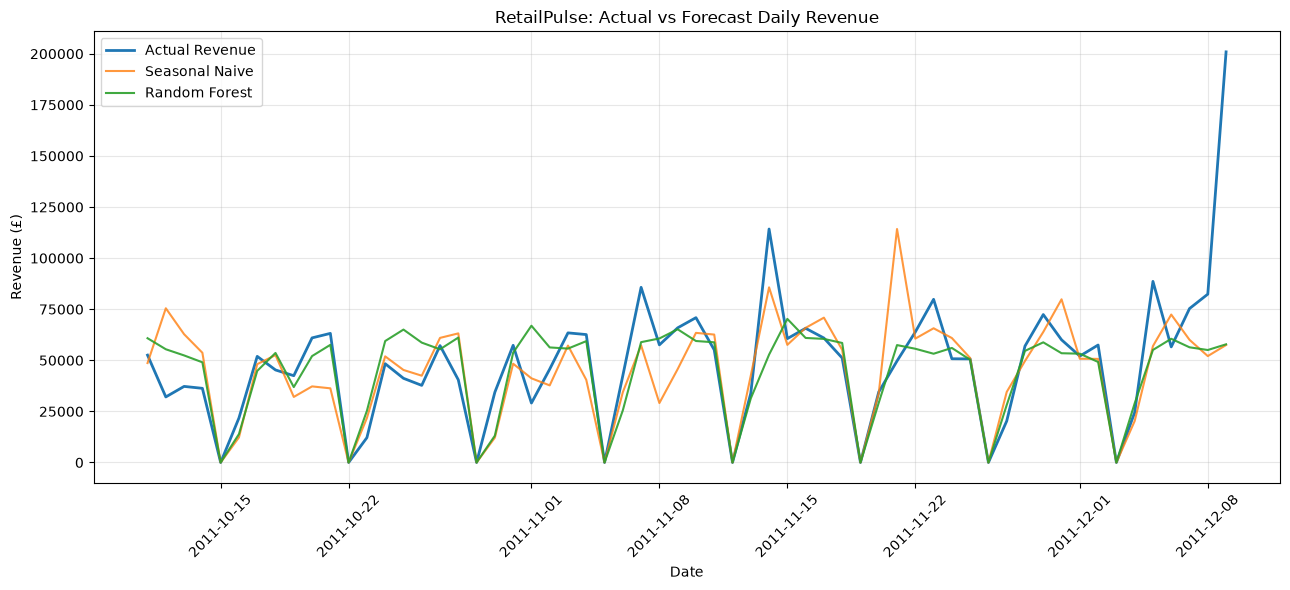


Forecast evaluation period:
2011-10-11 to 2011-12-09

Mean Absolute Error:
Seasonal Naive: £ 14104.06
Random Forest:  £ 12537.54
Chart saved to: c:\Users\Sahil Dabhekar\retailpulse\RetailPulse\data\processed\forecast_comparison.png


<Figure size 640x480 with 0 Axes>

In [4]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Locate the RetailPulse project root
ROOT = Path.cwd()

# If notebook is running from the notebooks folder, go up one level
if ROOT.name.lower() == "notebooks":
    ROOT = ROOT.parent

FILE = (
    ROOT
    / "data"
    / "processed"
    / "forecast_evaluation_predictions.csv"
)

# Verify the file exists
print("Project root:", ROOT)
print("Forecast file exists:", FILE.exists())

if not FILE.exists():
    raise FileNotFoundError(
        f"Forecast file not found: {FILE}\n"
        "Run src/forecasting_model.py from the project root first."
    )

# Load and sort forecast results
df = pd.read_csv(FILE, parse_dates=["Date"])
df = df.sort_values("Date")

# Plot actual revenue against both forecasting methods
plt.figure(figsize=(13, 6))

plt.plot(
    df["Date"],
    df["Actual_Revenue"],
    label="Actual Revenue",
    linewidth=2
)

plt.plot(
    df["Date"],
    df["Seasonal_Naive"],
    label="Seasonal Naive",
    alpha=0.8
)

plt.plot(
    df["Date"],
    df["Random_Forest"],
    label="Random Forest",
    alpha=0.9
)

plt.title("RetailPulse: Actual vs Forecast Daily Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue (£)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Display a quick evaluation summary
print("\nForecast evaluation period:")
print(df["Date"].min().date(), "to", df["Date"].max().date())

print("\nMean Absolute Error:")
print("Seasonal Naive: £", round(
    (df["Actual_Revenue"] - df["Seasonal_Naive"]).abs().mean(), 2
))
print("Random Forest:  £", round(
    (df["Actual_Revenue"] - df["Random_Forest"]).abs().mean(), 2
))

OUTPUT = ROOT / "data" / "processed" / "forecast_comparison.png"
plt.savefig(OUTPUT, dpi=150, bbox_inches="tight")
print("Chart saved to:", OUTPUT)


In [5]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()
if ROOT.name.lower() == "notebooks":
    ROOT = ROOT.parent

file_path = ROOT / "data" / "processed" / "customer_clusters.csv"
clusters = pd.read_csv(file_path)

print("Dataset shape:", clusters.shape)
print("\nCluster counts:")
print(clusters["Cluster"].value_counts().sort_index())

print("\nUnique customers:", clusters["Customer_ID"].nunique())

Dataset shape: (5878, 11)

Cluster counts:
Cluster
0    2699
1    3179
Name: count, dtype: int64

Unique customers: 5878
